In [ ]:
#You can ignore the comments, I just wanted to make myself feel smart by describing everything. WIP!!! Might need changes (Well not anymore).
#THIS CODE BELONGS TO THE MEMBERS: Alejandro Espinosa, Mariama Mansary and Rosanna Carreras. We became a group a little too late, so we dont have a team repository; Keep this in mind so you dont have to check the project in all of our repositories. Alejandro's respository is where all the work in the code was done.
#I retract what I just said, we ended up making a team repository. There we will just post the final result of our project and maybe other stuff if we have the time (Which is why you'll see the low commit score).
#ALRIGHT, so first, we have to get our tools ready.
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
#Extra thing here I decided to add based after hearing feedback, a dictionary! Which will contain the most important violations from our graphs and assign key words to them, this way we can then later do some cool stuff and include them on the graph so the stakeholder doesnt just see a number and a letter.
violation_keywords = {
    #The high impact ones
    "04K": "Rats",
    "04M": "Roaches",
    "05D": "Hand Washing",
    "04L": "Mice",
    "08A": "Pest Harborage",
    "02H": "Cooling Issues",
    "04N": "Filth Flies",
    "04A": "No Food Certificate",
    "02G": "Cold Food Temp",
    "04C": "Bare Hand Contact",
    "03A": "Food Source",
    #The not so high impact ones
    "10F": "Surface Material",
    "10E": "Thermometer",
    "08B": "Garbage Storage",
    "10A": "Toilet Supplies",
    "09E": "Wash Sign Missing",
    "10H": "Single Use Items",
    "10D": "Ventilation",
    "06D": "Surface Cleaning",
    "10B": "Drainage",
    "10G": "Dishwashing",
    "10I": "Service Item"
}

In [3]:
#Before we begin, we load the data of course (Had so much trouble with this at first for some reason.) The table we'll be focusing on here only contains significant columns for us such as ID (CAMIS), BORO, GRADE, VIOLATION CODE AND DESCRIPTION, CUISINE, SCORE, and INSPECTION_DATE.
df = pd.read_csv(r"C:\Users\Ale\OneDrive\Desktop\Python Econ\Alejandro-Espinosa_Spring-2026\Project\data\Full Table for Analysis V3!.csv")

In [4]:
#Alright so to start, we first convert INSPECTION_DATE to datetime from just plain text, so we can work with it properly, just trust me, it'll allow us to do some math in a bit since we really cant with strings.
df["INSPECTION_DATE"] = pd.to_datetime(df["INSPECTION_DATE"])

In [5]:
#Alright, so we actually decided here to add a time frame to our data (why we needed that last code), something we didn't do before! 
#For this, I just decided to make my life easier by finding the most recent inspection date in our data with max, and then subtract 2 years from it.
#This then gives us our cutoff point which means that anything before this date will be filtered out, we decided to go with more recent data as the stakeholder will find much more meaning here rather than old data when times we're different. Before COVID hit for example.
cutoff = df["INSPECTION_DATE"].max() - pd.DateOffset(years=2)
#This right here then allows us to only keep rows where the inspection date is on or after our cutoff.
df = df[df["INSPECTION_DATE"] >= cutoff]

Key Question: Which violations show up most often in "clean" inspections?

In [6]:
#Well before we answer that question, we first have to define our metric. What defines failure exactly? Well, we'll get to that in a bit.
#First we create a new column called CLEAN, where a row is only true IF THE GRADE IS AN A AND THE SCORE IS BELOW 10.
#Why? Well because the stakeholders metric was said to be the limit 10! And we be very specific about this because A can go up to 13 points! And believe it or not, there's some C grades that also have below 10 points. (Have no clue as to how.)
df["CLEAN"] = (df["GRADE"] == "A") & (df["SCORE"] < 10)

#Now a quick little check, what portion of our data sits in our clean zone?
df["CLEAN"].value_counts()

CLEAN
False    746936
True     146524
Name: count, dtype: int64

In [7]:
#Woah, quite the difference.
#Now moving on, we must understand that SCORE in this table, is the total score per inspection visit, not per individual violation. I say this because based on what I saw, if one inspection had 5 violations let's say, then all 5 rows would show the same score.
#Therefore, to avoid double counting, I decided to drop duplicates based on restaurant ID plus the inspection date.
#So each remaining row now represents one unique inspection visit.
inspections = df.drop_duplicates(subset=["CAMIS", "INSPECTION_DATE"])
#Now this right here, is the meat of our data.
inspections["CLEAN"].value_counts()

CLEAN
False    18960
True     10530
Name: count, dtype: int64

In [8]:
#Now lets truly begin answering the question. To do this, we pretty much just group every row in inspections by its violation code
#Then for each group, calculate two things from the CLEAN column:
#The mean which if we took stats before, is the proportion of rows that are True (the clean rate as a decimal)
#And the count, which is how many times that violation code appears in our data. (Added this after I did the chart beacuse I noticed it was one of its flaws, it'll help with analysis on frequency of the data, despite not having higher rates.)
#Then for simplicity sake, I renamed those columns to something more easier to digest.
summary = (
    inspections.groupby("VIOLATION_CODE")["CLEAN"]
    .agg(["mean", "count"])
    .rename(columns={"mean": "clean_rate", "count": "count"})
)
#Here of course we convert the decimal clean rate into a percent so it's easier to read before we chart
summary["clean_rate_%"] = summary["clean_rate"] * 100

#And here we keep only violations with 100+ observations to avoid misleading results
summary = summary[summary["count"] > 100]

In [9]:
#Alright, you'll see a code similar to this before charting everytime. What I do is I just sort descending by clean rate and grab the top 10
#Which will show the violation codes that appear most often in clean inspections, which is what we want to show to the stakeholder.
clean_violations = summary.sort_values("clean_rate_%", ascending=False).head(10)

#Here is where that dictionary comes into play, here what mapping allows us to do is swap each code for its keywords we defined earlier! We also include the count and finally build the label by adding both of them.
keywords = clean_violations.index.map(violation_keywords)
counts = clean_violations["count"].astype(str)
clean_violations["label"] = keywords + " (" + counts + ")"

In [10]:
#Did some digging on how to make the charts, well, look better, before charting and found this on the book! Seaborn apparently has themes I didnt know about, and white grid looks good if you ask me.
sns.set(style="whitegrid")

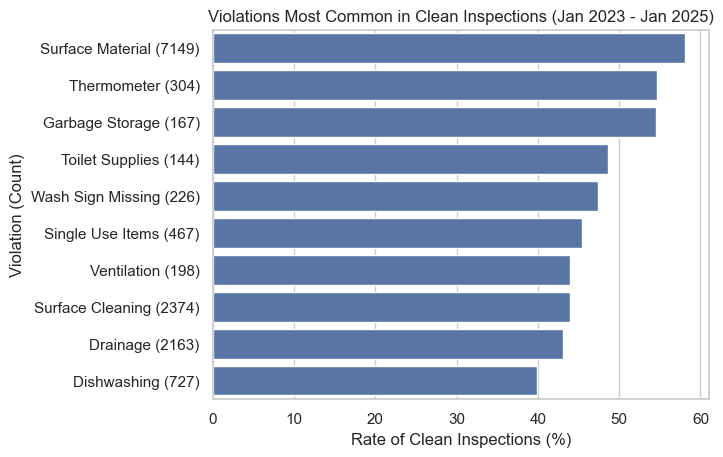

In [11]:
#Lastly, here, I just created the chart using seaborn, following the steps on the site and book :D
sns.barplot(x="clean_rate_%", y="label", data=clean_violations)

plt.xlabel("Rate of Clean Inspections (%)")
plt.ylabel("Violation (Count)")
plt.title("Violations Most Common in Clean Inspections (Jan 2023 - Jan 2025)")
plt.show()

In [12]:
#Tadaaa; BUT WAIT, before moving onto the next relationship, I actually decided to include the negative results aswell! Since it will help the stakeholder even more:
#So instead, we now flip the question, which violation codes almost always result in higher scores? These are the bad boys that dare past the 10 point limit the most.
#From here, we pretty much follow the same code and format with just a few changes, this time, we'll use score instead of our clean column, because when I tried that I just got straight up zero's (which makes sense), so, we'll find the mean score per violation code that will then tell us how much each violation tends to increase the total score, and that are above 10 of course.
score_summary = (
    inspections.groupby("VIOLATION_CODE")["SCORE"]
    .agg(["mean", "count"])
    .rename(columns={"mean": "avg_score", "count": "count"})
)

score_summary = score_summary[score_summary["count"] > 100]

risky_violations = score_summary.sort_values("avg_score", ascending=False).head(10)


keywords = risky_violations.index.map(violation_keywords)
counts = risky_violations["count"].astype(str)
risky_violations["label"] = keywords + " (" + counts + ")"

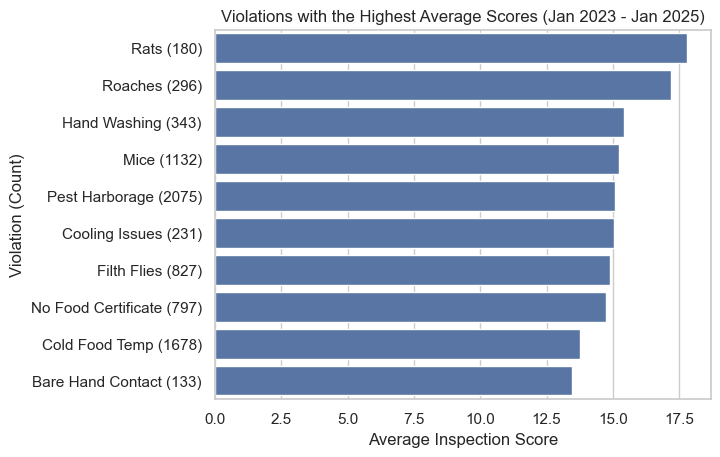

In [13]:
#Now here's the evil chart.
sns.barplot(x="avg_score", y="label", data=risky_violations)

plt.xlabel("Average Inspection Score")
plt.ylabel("Violation (Count)")
plt.title("Violations with the Highest Average Scores (Jan 2023 - Jan 2025)")
plt.show()

Key Question 2: Which boroughs have the highest clean rates?

In [14]:
#Now moving on, we'll focus on Boroughs that have the highest clean rates, clean remember, being grade A and below 10 points (our metric).
#From here on out, its just a similar format with a few tweaks here and there.
borough = (
    inspections.groupby("BORO")["CLEAN"]
    .agg(["mean", "count"])
    .rename(columns={"mean": "clean_rate", "count": "count"})
)

borough["clean_rate_%"] = borough["clean_rate"] * 100
borough = borough.sort_values("clean_rate_%", ascending=False)

In [89]:
#However, one thing I decided to add on here, is a new column to tell the difference from the mean for each borough (Why did I add this? Well, because a raw number alone is kind of meaningless, if we see a percent on a graph, how would we know its good or bad? We need something to compare it to, and that's where the avg comes in.
avg = inspections["CLEAN"].mean() * 100
borough["diff_from_avg"] = borough["clean_rate_%"] - avg

print(round(avg, 1))
borough

35.7


,clean_rate,count,clean_rate_%,diff_from_avg
BORO,,,,
Manhattan,0.376317,11198,37.631720,1.924701
Brooklyn,0.376061,7895,37.606080,1.899060
Staten Island,0.346712,1171,34.671221,-1.035798
Bronx,0.331234,2699,33.123379,-2.583640
Queens,0.313620,6527,31.362035,-4.344985


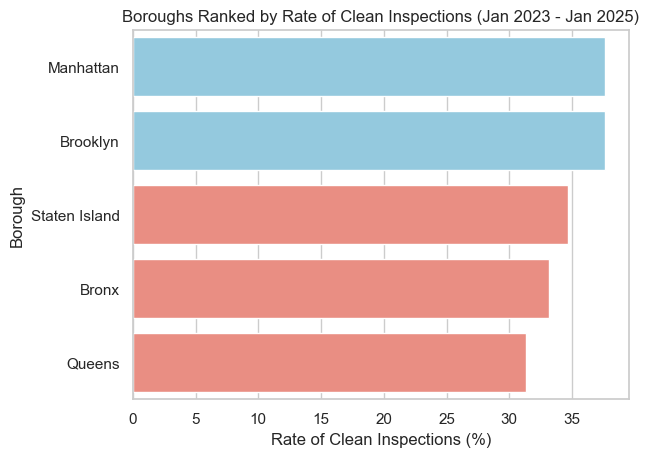

In [90]:
#And now for the chart; We'll use color bars to indentify which are below and above the average to see if they really are good or bad scores!
#First, we can build a list of bar colors based on whether each borough is above or below the average
#Which we then loop through the diff_from_avg column row by row to decide each color! In this case, blue will be good (above the mean), and red will be bad (below the mean), pretty cliche i know. (Went with lighter versions of said colors since it was killing my eyes.)
colors = []
for v in borough["diff_from_avg"]:
    if v > 0:
        colors.append("skyblue")
    else:
        colors.append("salmon")

#Here, we create a dictionary that will allow us to pair each borough name with its corresponding color so seaborn knows which bar gets which color!! (This was such a headache, and why use a dict this time rather than a list? Because then seaborn would start acting up; Plus, a list could store the colors but wouldn't link them to specific borough names.)
borough_colors = {}
for boro_name, color in zip(borough.index, colors):
    borough_colors[boro_name] = color

sns.barplot(
    x="clean_rate_%",
    y=borough.index,
    data=borough,
    #Extra things seaborn told me to follow, has to do with showing the colors.
    hue=borough.index,
    palette=borough_colors,
)
plt.xlabel("Rate of Clean Inspections (%)")
plt.ylabel("Borough")
plt.title("Boroughs Ranked by Rate of Clean Inspections (Jan 2023 - Jan 2025)")
plt.show()

Key Question 3: Which cuisines have the highest clean rates?

In [91]:
#Now again, VERY similiar format, just that we'll slice it two ways (best and worst) afterwards.
cuisine_full = (
    inspections.groupby("CUISINE_DESCRIPTION")["CLEAN"]
    .agg(["mean", "count"])
    .rename(columns={"mean": "clean_rate", "count": "count"})
)

cuisine_full["clean_rate_%"] = cuisine_full["clean_rate"] * 100

#Here I decided to chose 200 rather than 100 because there are just many more cuisine entries than in violations.
cuisine_full = cuisine_full[cuisine_full["count"] > 200]

#Now here, I actually noticed that the table contains cuisine types such as "Not Listed/Not Applicable" and "Other", which cmon, doesnt tell anything to the stakeholder. So i decided to remove it just in case (one actually appeared in the graph funny enough) using !=, which just means not equal.
cuisine_full = cuisine_full[cuisine_full.index != "Not Listed/Not Applicable"]
cuisine_full = cuisine_full[cuisine_full.index != "Other"]

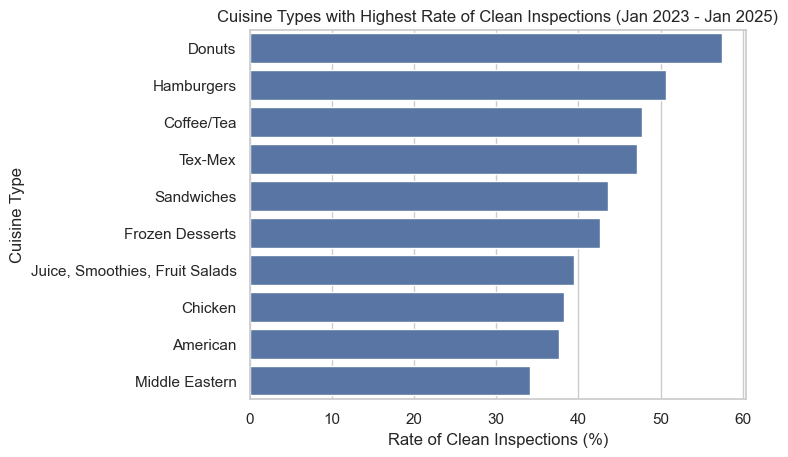

In [92]:
#Now, we're ready for the chart, couldnt think of any fancy things to add here sadly, so we'll just take the top 10 cuisines by clean rate.
cuisine_best = cuisine_full.sort_values("clean_rate_%", ascending=False).head(10)

sns.barplot(x="clean_rate_%", y=cuisine_best.index, data=cuisine_best)

plt.xlabel("Rate of Clean Inspections (%)")
plt.ylabel("Cuisine Type")
plt.title("Cuisine Types with Highest Rate of Clean Inspections (Jan 2023 - Jan 2025)")
plt.show()

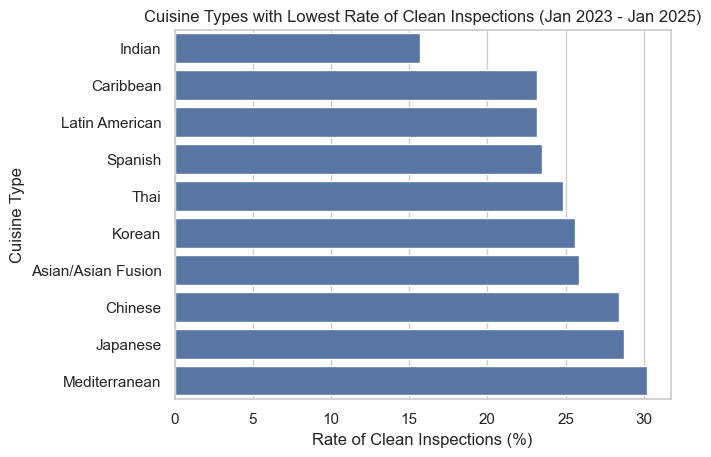

In [93]:
#And here I decided to also include the negative results like we did in violations, but thankfully its way easier here, since we can just literally flip the data.
cuisine_worst = cuisine_full.sort_values("clean_rate_%", ascending=True).head(10)

sns.barplot(x="clean_rate_%", y=cuisine_worst.index, data=cuisine_worst)

plt.xlabel("Rate of Clean Inspections (%)")
plt.ylabel("Cuisine Type")
plt.title("Cuisine Types with Lowest Rate of Clean Inspections (Jan 2023 - Jan 2025)")
plt.show()

Merge between Key Question 2 and 3!

In [94]:
#Now taking the professors advice, I decide to merge the two charts of both borughs and cuisine types, to see how each cuisine performs across different boroughs!
#So first, we get the names of the top 8 cuisines by clean rate, chose 8 here because we're actually going to do a grouped bar chart for this, and I dont want it to look more packed than it already is.
#Here you may see that little .index at the end, this will actually gives us just the cuisine names (the rows), not the full dataframe
top_cuisines = cuisine_full.sort_values("clean_rate_%", ascending=False).head(8).index

#Here, we filter the inspections table down to only those top 8 cuisines using .isin(), which pretty much returns true for rows whose cuisine matches any of our top 8
merge_data = inspections[inspections["CUISINE_DESCRIPTION"].isin(top_cuisines)]

#Now here it got a little tricky; because after we group by both borough AND cuisine to get the clean rate for every borough and cuisine combo
#We have to use reset_index(), which converts the grouped result back into a regular dataframe. Why? For easier plotting.
merge_summary = (
    merge_data.groupby(["BORO", "CUISINE_DESCRIPTION"])["CLEAN"]
    .mean()
    .reset_index()
)
merge_summary["clean_rate_%"] = merge_summary["CLEAN"] * 100

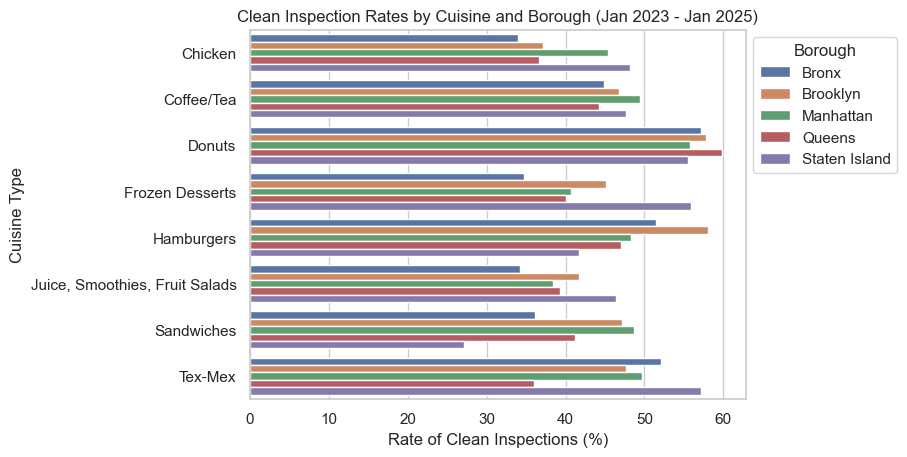

In [95]:
#And now here's the group bar chart, wasnt as hard as I thought it would be, since seaborn handles the grouping for us with the hue parameter (now i know what it means lol)
sns.barplot(
    x="clean_rate_%",
    y="CUISINE_DESCRIPTION",
    hue="BORO",
    data=merge_summary
)

plt.xlabel("Rate of Clean Inspections (%)")
plt.ylabel("Cuisine Type")
plt.title("Clean Inspection Rates by Cuisine and Borough (Jan 2023 - Jan 2025)")
plt.legend(title="Borough", bbox_to_anchor=(1, 1)) #This just help keeping that little box you see giving colors to the boroughs in a safe place, nowwhere near the chart that is. This way we can see what color is what Borough.
plt.show()

In [96]:
#Now before ending things off; Since the stakeholder mentioned they wanted to open up a pizza restaurant. Let's actually compare it to the top 8 cuisines we just found!
#We simply just build a list combining our top 8 cuisines plus the pizza since we know that lists are mutable, so we can add stuff to it!
my_list = list(top_cuisines) + ["Pizza"]

#And then we simply filter cuisine_full to only include those cuisines
pizza_add = cuisine_full[cuisine_full.index.isin(my_list)]
pizza_add = pizza_add.sort_values("clean_rate_%", ascending=False)

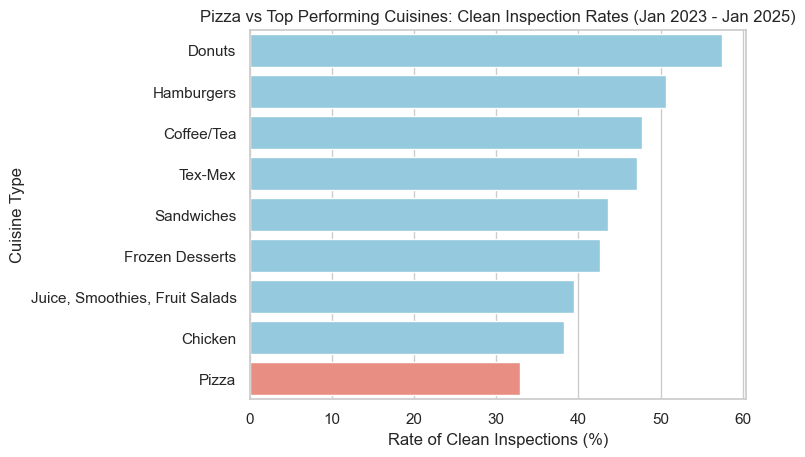

In [97]:
#Here's kind of the same thing as Chart number 2! Just that we make pizza the red color now since its already below the mean really.
colors = []
for cuisine in pizza_add.index:
    if cuisine == "Pizza":
        colors.append("salmon")
    else:
        colors.append("skyblue")

cuisine_colors = {}
for cuisine_name, color in zip(pizza_add.index, colors):
    cuisine_colors[cuisine_name] = color


avg_clean = inspections["CLEAN"].mean() * 100

sns.barplot(
    x="clean_rate_%",
    y=pizza_add.index,
    data=pizza_add,
    hue=pizza_add.index,
    palette=cuisine_colors,
)

plt.xlabel("Rate of Clean Inspections (%)")
plt.ylabel("Cuisine Type")
plt.title("Pizza vs Top Performing Cuisines: Clean Inspection Rates (Jan 2023 - Jan 2025)")
plt.show()

And we can see here that pizza, just may not be that much of a great choice. But if it still is the choice, then the earlier graphs such as boroughs and violations can help the stakeholder keep their score below a 10 despite going ride or die with pizza. (Cant blame him there, pizza is awesome.)

In [98]:
#Now I had a change of heart, I decided to include an extra graph, because my gut is telling me something. This time, we'll see how pizza performs per borough! Why do I do this depsite just saying we can use the one we made already? Well because this way, if pizza still remains the choice, the stakeholder can see if the previous graph of clean rates per borough also applies to pizza aswell, afterall, data can be missleading ;)
#First we filter the data to only include pizza inspections, then group by borough.
#And after, smooth sailing, same format as other charts.
pizza = inspections[inspections["CUISINE_DESCRIPTION"] == "Pizza"]

pizza_borough = (
    pizza.groupby("BORO")["CLEAN"]
    .agg(["mean", "count"])
    .rename(columns={"mean": "clean_rate", "count": "count"})
)

pizza_borough["clean_rate_%"] = pizza_borough["clean_rate"] * 100
pizza_borough = pizza_borough.sort_values("clean_rate_%", ascending=False)

In [99]:
#Here its a little different, of course first we calculate the average, but this time, its the overall pizza clean rate so we can compare each borough to the pizza average specifically.
#We could use the overall NYC average sure, but pizza vs pizza feels like a fairer comparison here honestly.
pizza_avg = pizza["CLEAN"].mean() * 100
pizza_borough["diff_from_avg"] = pizza_borough["clean_rate_%"] - pizza_avg

print(round(pizza_avg, 1))
pizza_borough

32.9


,clean_rate,count,clean_rate_%,diff_from_avg
BORO,,,,
Brooklyn,0.351779,506,35.177866,2.263705
Bronx,0.339100,289,33.910035,0.995874
Queens,0.335000,400,33.500000,0.585839
Manhattan,0.313373,501,31.337325,-1.576835
Staten Island,0.263158,133,26.315789,-6.598371


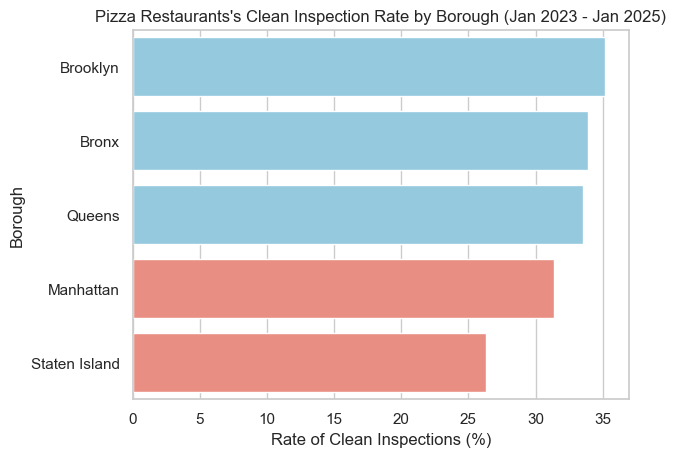

In [100]:
#And the chart, same thing as the others.
colors = []
for v in pizza_borough["diff_from_avg"]:
    if v > 0:
        colors.append("skyblue")
    else:
        colors.append("salmon")

pizza_borough_colors = {}
for borough_name, color in zip(pizza_borough.index, colors):
    pizza_borough_colors[borough_name] = color

sns.barplot(
    x="clean_rate_%",
    y=pizza_borough.index,
    data=pizza_borough,
    hue=pizza_borough.index,
    palette=pizza_borough_colors,
)
plt.xlabel("Rate of Clean Inspections (%)")
plt.ylabel("Borough")
plt.title("Pizza Restaurants's Clean Inspection Rate by Borough (Jan 2023 - Jan 2025)")
plt.show()

And boom! My gut was right, while manhattan may have a higher clean inspection rate than other boroughs, for pizza specifically, it doesnt! Therefore brooklyn is the best choice here! It also reinforces our merged cuisine chart, where it shows how borough is very dependent on cuisine types.

In [101]:
#You can ignore this; This is just the data we'll be needing for the Dashboard, difference from the original is that this one is filtered to have the time frame of 2 years that we coded earlier into it. The original one isnt. Why? Because a dashboard is supposed to give more recent data!
inspections.to_csv(r"C:\Users\Ale\OneDrive\Desktop\Python Econ\Alejandro-Espinosa_Spring-2026\Project\data\dashboard_data.csv", index=False)

In [102]:
#And here what I was talking about earlier when I said some scores are below 10 without an A grade! (Genuinely how.)
df[(df["SCORE"] < 10) & (df["GRADE"] != "A")]["GRADE"].value_counts()

GRADE
C    1313
Name: count, dtype: int64

Below is for the feedback I got from the professor. Here I decided to include some the same graphs we did before (as some of them would be pretty useless based on what we're about to do), which is taking into account the full time frame now, just not two years! This way we can see how much things from the past affect our data and record it on our report as the report should also include data from every time frame! For this, we pretty much follow the same code format, so I wont bother explaining it.

In [103]:
df_full = pd.read_csv(r"C:\Users\Ale\OneDrive\Desktop\Python Econ\Alejandro-Espinosa_Spring-2026\Project\data\Full Table for Analysis V3!.csv")


df_full["INSPECTION_DATE"] = pd.to_datetime(df_full["INSPECTION_DATE"])

#Here's a quick little thing I decided to add for the funsies, to show you what dataset we're woking with now. As we can see, its all the way back from 2011!! (You can ignore those 00:00's there.)
print(df_full['INSPECTION_DATE'].min(), df_full['INSPECTION_DATE'].max())
print(len(df_full))

2011-01-25 00:00:00 2025-01-02 00:00:00
1424870


In [104]:
#Then from here, pretty familiar stuff
df_full["CLEAN"] = (df_full["GRADE"] == "A") & (df_full["SCORE"] < 10)


inspections_full = df_full.drop_duplicates(subset=["CAMIS", "INSPECTION_DATE"])

In [105]:
score_summary_full = (
    inspections_full.groupby("VIOLATION_CODE")["SCORE"]
    .agg(["mean", "count"])
    .rename(columns={"mean": "avg_score", "count": "count"})
)

score_summary_full = score_summary_full[score_summary_full["count"] > 100]

risky_violations_full = score_summary_full.sort_values("avg_score", ascending=False).head(10)

keywords = risky_violations_full.index.map(violation_keywords)
counts = risky_violations_full["count"].astype(str)
risky_violations_full["label"] = keywords + " (" + counts + ")"

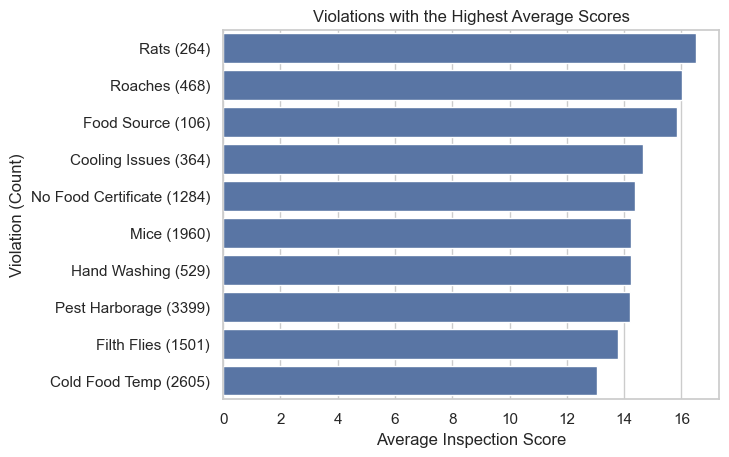

In [106]:
sns.barplot(x="avg_score", y="label", data=risky_violations_full)

plt.xlabel("Average Inspection Score")
plt.ylabel("Violation (Count)")
plt.title("Violations with the Highest Average Scores")
plt.show()

Big switch here is that Food source jumping all the way up to the top 3, woah!

In [107]:
summary_full = (
    inspections_full.groupby("VIOLATION_CODE")["CLEAN"]
    .agg(["mean", "count"])
    .rename(columns={"mean": "clean_rate", "count": "count"})
)

summary_full["clean_rate_%"] = summary_full["clean_rate"] * 100
summary_full = summary_full[summary_full["count"] > 100]

clean_violations_full = summary_full.sort_values("clean_rate_%", ascending=False).head(10)

keywords = clean_violations_full.index.map(violation_keywords)
counts = clean_violations_full["count"].astype(str)
clean_violations_full["label"] = keywords + " (" + counts + ")"

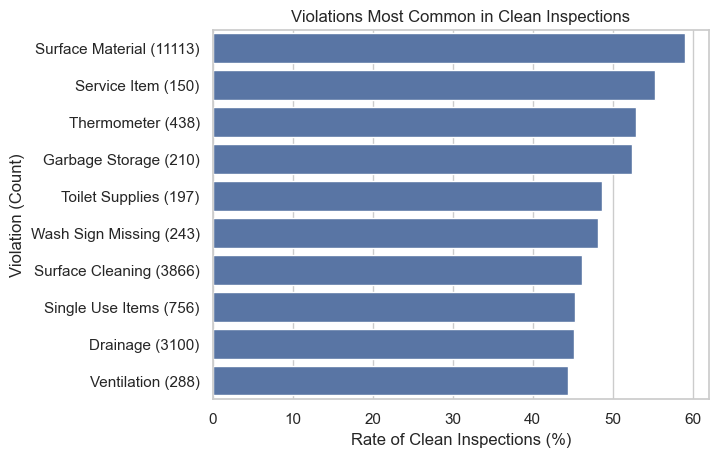

In [108]:
sns.barplot(x="clean_rate_%", y="label", data=clean_violations_full)

plt.xlabel("Rate of Clean Inspections (%)")
plt.ylabel("Violation (Count)")
plt.title("Violations Most Common in Clean Inspections")
plt.show()

Major switch here is that service item, which was nowhere to be seen back in our 2 year range chart.

In [109]:
borough_full = (
    inspections_full.groupby("BORO")["CLEAN"]
    .agg(["mean", "count"])
    .rename(columns={"mean": "clean_rate", "count": "count"})
)

borough_full["clean_rate_%"] = borough_full["clean_rate"] * 100
borough_full = borough_full.sort_values("clean_rate_%", ascending=False)


avg_full = inspections_full["CLEAN"].mean() * 100
borough_full["diff_from_avg"] = borough_full["clean_rate_%"] - avg_full

print(round(avg_full, 1))
borough_full

37.4


,clean_rate,count,clean_rate_%,diff_from_avg
BORO,,,,
Brooklyn,0.393010,12389,39.300993,1.917937
Manhattan,0.391138,17536,39.113823,1.730767
Bronx,0.345029,3933,34.502924,-2.880132
Queens,0.339665,10266,33.966491,-3.416564
Staten Island,0.331882,1838,33.188248,-4.194807


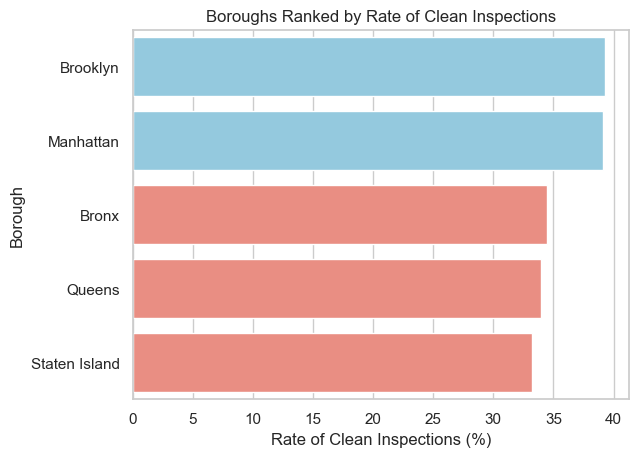

In [110]:
colors = []
for v in borough_full["diff_from_avg"]:
    if v > 0:
        colors.append("skyblue")
    else:
        colors.append("salmon")

borough_full_colors = {}
for boro_name, color in zip(borough_full.index, colors):
    borough_full_colors[boro_name] = color

sns.barplot(
    x="clean_rate_%",
    y=borough_full.index,
    data=borough_full,
    hue=borough_full.index,
    palette=borough_full_colors,
)
plt.xlabel("Rate of Clean Inspections (%)")
plt.ylabel("Borough")
plt.title("Boroughs Ranked by Rate of Clean Inspections")
plt.show()

Not much dramatic changes here honestlty, just that brooklyn ended up taking the cake over manhatan by the smallest margin i've seen, still, these two have surely remain consistent over the years.

In [111]:
cuisine_full_v2 = (
    inspections_full.groupby("CUISINE_DESCRIPTION")["CLEAN"]
    .agg(["mean", "count"])
    .rename(columns={"mean": "clean_rate", "count": "count"})
)

cuisine_full_v2["clean_rate_%"] = cuisine_full_v2["clean_rate"] * 100
cuisine_full_v2 = cuisine_full_v2[cuisine_full_v2["count"] > 200]
cuisine_full_v2 = cuisine_full_v2[cuisine_full_v2.index != "Not Listed/Not Applicable"]
cuisine_full_v2 = cuisine_full_v2[cuisine_full_v2.index != "Other"]

cuisine_best_full = cuisine_full_v2.sort_values("clean_rate_%", ascending=False).head(10)

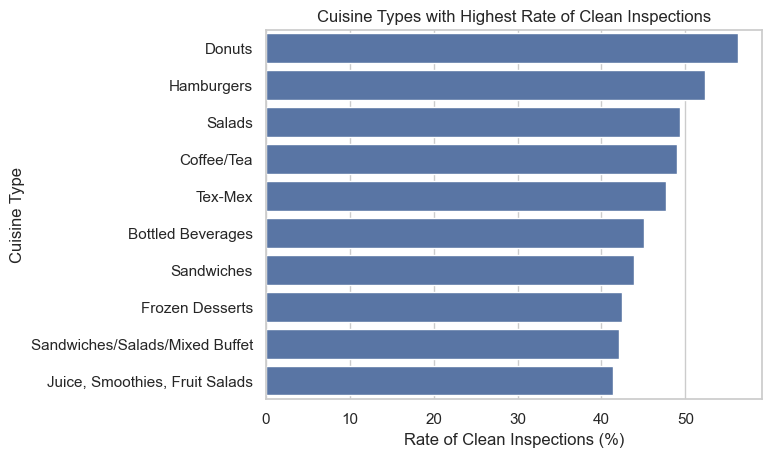

In [112]:
sns.barplot(x="clean_rate_%", y=cuisine_best_full.index, data=cuisine_best_full)

plt.xlabel("Rate of Clean Inspections (%)")
plt.ylabel("Cuisine Type")
plt.title("Cuisine Types with Highest Rate of Clean Inspections")
plt.show()

And lastly, here we can see a pretty big change as well, salads fell off pretty bad in our 2 year chart, some research will have to be done to this because even im curious now.

And you've reached the end. Thank you for taking the time to read our hard work, and hope you've enjoyed it!

You can actually ignore this at the bottom, is just me testing and trying to somehow get API data and get it to the dashboard (Spoilers, It didnt go well.)

In [113]:
import requests
api_url = "https://data.cityofnewyork.us/resource/43nn-pn8j.json?$limit=1000"

response = requests.get(api_url)
api_data = response.json()

df_api = pd.DataFrame(api_data)

In [114]:
df_api["inspection_date"] = pd.to_datetime(df_api["inspection_date"])
print(df_api['inspection_date'].min())
print(df_api['inspection_date'].max())

1900-01-01 00:00:00
2026-05-16 00:00:00


In [115]:
print(df['INSPECTION_DATE'].max())

2025-01-02 00:00:00


So, the most recent data given to us is May of 2026, which compared to the max date given to us, being 2025 of january, i'd say its not the biggest difference, therefore I dont think it's worth setting up an API on our dashboard because the gap is not that big, and will most likely not produce much changes, only very tiny ones. (Im coping right now if you couldn't tell, I know you dont like when people guess and thats pretty much what I just did, but setting this thing up is actually a headache on top of all this studying for finals, so ill take you up on that "optional" word of yours there and give this little excuse to get lazy :p)